In [1]:
# Imports required for the semi-supervised experiment
import copy
import random
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from transformers import AutoTokenizer, AutoModel

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

from tqdm.auto import tqdm

# Keep all experiments reproducible
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


c:\Users\Setayesh\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Semi-Supervised Learning with ParsBERT

## Objective

In this notebook, we investigate whether pseudo-labeling can improve a fine-tuned ParsBERT model for Persian Digikala review classification.

The experiment focuses on the `recommendation_status` task only.

## Experiment Pipeline

1. **Hide 20% of the labels:** from `train_experiment_500k.csv`, select 20% of each class with a stratified `train_test_split` (fixed seed). These samples become `train_pseudo_unlabeled` (labels removed). The remaining 80% become `train_supervised`.
2. **Supervised training:** fine-tune ParsBERT only on the labeled 80% (`train_supervised`). This is the **supervised baseline**.
3. **Pseudo-labeling:** use the baseline to predict the hidden 20%. Keep only predictions with confidence >= 0.90.
4. **Semi-supervised training:** train a new model, with the same initialization, hyperparameters and seed as the baseline, on `train_supervised` + accepted pseudo-labeled samples.
5. **Evaluation on two datasets:** both models are evaluated on the validation set (`validation_50k_corrected.csv`) and the test set (`test.csv`).
6. **Comparison:** supervised vs. semi-supervised (metrics, per-class reports, confusion matrices, statistical test), plus an audit of pseudo-label quality against the hidden reference labels.

## Fair-comparison design

- Both models start from the same pretrained ParsBERT weights and the same random seed (identical classifier-head initialization).
- Both use the same learning rate, weight decay, batch size, epochs, early-stopping rule and validation set.
- The semi-supervised model is trained from scratch on the combined data; it is **not** a continuation of the baseline, so it does not receive extra training steps on the labeled data.
- The validation set is used for early stopping/checkpoint selection of both models, so it is not a fully untouched evaluation set. The test set is never used for training, pseudo-labeling, or model selection.
- Pseudo-label quality is audited against the hidden reference labels only after pseudo-label selection and training.

## Google Colab Setup

This notebook can run locally or in Google Colab. For Colab, mount the Google Drive account that contains the project files. Keep the input datasets, generated CSV files, and model checkpoints in the same project folder so they remain available after a runtime disconnect.

**Expected Google Drive structure:**

```text
MyDrive/
└── digikala_comments/
    ├── data/
    │   ├── train_experiment_500k.csv
    │   ├── validation_50k_corrected.csv
    │   └── test.csv
    └── models/
```

If your folder has a different name or location, change `PROJECT_DIR` in the next cell. If the project folder is shared from another Google account, add a shortcut to it in the Colab account's `My Drive` first.

In [21]:
# Google Colab: mount Google Drive
from google.colab import drive
drive.mount("/content/drive")

# Change this path if your project folder has a different name/location.
PROJECT_DIR = Path("/content/drive/MyDrive/digikala_comments")

# All input data, generated datasets, and checkpoints are stored in Drive.
DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "models"

# DATA_DIR.mkdir(parents=True, exist_ok=True)
# MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Check that the required original datasets are available.
required_files = [
    DATA_DIR / "train_experiment_500k.csv",
    DATA_DIR / "validation_50k_corrected.csv",
    DATA_DIR / "test.csv",
]

for file_path in required_files:
    print(f"{'FOUND' if file_path.exists() else 'MISSING'}: {file_path}")

if not all(file_path.exists() for file_path in required_files):
    raise FileNotFoundError(
        "One or more required CSV files are missing. "
        "Check PROJECT_DIR and the data folder in Google Drive."
    )

print("\nProject directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)
print("Model directory:", MODEL_DIR)

ModuleNotFoundError: No module named 'google.colab'

In [22]:
# Change this path if your project folder has a different name/location.
PROJECT_DIR = Path("..")

# All input data, generated datasets, and checkpoints are stored in Drive.
DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "models"

# Check that the required original datasets are available.
required_files = [
    DATA_DIR / "train_experiment_500k.csv",
    DATA_DIR / "validation_50k_corrected.csv",
    DATA_DIR / "test.csv",
    DATA_DIR / "test_10k_corrected.csv",
]

for file_path in required_files:
    print(f"{'FOUND' if file_path.exists() else 'MISSING'}: {file_path}")

if not all(file_path.exists() for file_path in required_files):
    raise FileNotFoundError(
        "One or more required CSV files are missing. "
        "Check PROJECT_DIR and the data folder in Google Drive."
    )

print("\nProject directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)
print("Model directory:", MODEL_DIR)

FOUND: ..\data\train_experiment_500k.csv
FOUND: ..\data\validation_50k_corrected.csv
FOUND: ..\data\test.csv
FOUND: ..\data\test_10k_corrected.csv

Project directory: ..
Data directory: ..\data
Model directory: ..\models


### Check the Colab Runtime

Before starting model training, confirm that Colab assigned a GPU. In Colab, select **Runtime → Change runtime type → T4 GPU** (if available), then run the next cell. The notebook will still run on CPU if no GPU is available, but training will be much slower.

In [ ]:
# Check whether a GPU is available
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU is not available. Training will run on CPU.")

Device: cuda
GPU: Tesla T4


In [3]:
import torch

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cpu


**Run order:** run the imports cell, the Google Drive setup cell, the GPU check, and then execute the notebook cells from top to bottom. After a runtime disconnect, remount Drive, rerun the setup/import/configuration/data/model/function cells, and rerun the relevant training cell. The training function automatically checks its latest checkpoint.

## Creating the Artificial Unlabeled Dataset for Semi-Supervised Learning

In this step, we create an artificial unlabeled dataset from the original labeled training data to evaluate the effectiveness of semi-supervised learning.

The main idea is to hide the labels of a portion of the training samples and use these samples as unlabeled data for pseudo-labeling.

### Masking Procedure

1. Start with the original labeled training dataset (`train_experiment_500k.csv`).
2. Split it once with `train_test_split` using `test_size=0.20`, `stratify=recommendation_status` and a fixed `random_state`, so exactly 20% of every class is selected.
3. Save the selected 20% in `train_pseudo_unlabeled.csv`, keeping only their `id` and text content.
4. Save the remaining 80% in `train_supervised.csv`, preserving their original labels.

### Purpose

The resulting datasets are used in two stages:

- **Supervised Training:** The model is initially fine-tuned using the remaining 80% of labeled training samples.
- **Pseudo-Labeling:** The trained model predicts labels for the artificially unlabeled 20% of training samples. Predictions with a confidence score of at least 0.90 are selected for the next training stage.

This approach allows us to investigate whether adding high-confidence pseudo-labeled samples can improve the model's performance compared with supervised training alone.

**Important:** The original dataset remains unchanged. The artificial unlabeled dataset is created by removing labels only from the selected copies of training samples. Validation and test datasets are never used for masking or pseudo-labeling.

In [4]:
import pandas as pd

train_df = pd.read_csv(DATA_DIR / "train_experiment_500k.csv")

print("Shape:", train_df.shape)
print("\nColumns:")
print(train_df.columns.tolist())

print("\nRecommendation class distribution:")
print(train_df["recommendation_status"].value_counts(dropna=False))

Shape: (500000, 5)

Columns:
['id', 'product_id', 'text', 'recommendation_status', 'rate']

Recommendation class distribution:
recommendation_status
recommended        166670
no_idea            166665
not_recommended    166665
Name: count, dtype: int64


In [5]:
# Check ID quality
print("Missing IDs:", train_df["id"].isna().sum())
print("Duplicate IDs:", train_df["id"].duplicated().sum())

# Check missing recommendation labels
print(
    "Missing recommendation labels:",
    train_df["recommendation_status"].isna().sum()
)

# Check unique recommendation classes
print(
    "Recommendation classes:",
    train_df["recommendation_status"].unique()
)

Missing IDs: 0
Duplicate IDs: 0
Missing recommendation labels: 0
Recommendation classes: <StringArray>
['recommended', 'no_idea', 'not_recommended']
Length: 3, dtype: str


### Selecting 20% of Samples from Each Class

In [ ]:
from sklearn.model_selection import train_test_split

# Masking configuration
MASK_RATE = 0.20
MASK_SEED = 42

### Selecting Masked Samples

A single stratified split keeps the class proportions identical in both parts.

In [ ]:
# Stratified split: 80% stays labeled, 20% will be treated as unlabeled
_, masked_part_df = train_test_split(
    train_df,
    test_size=MASK_RATE,
    stratify=train_df["recommendation_status"],
    random_state=MASK_SEED,
    shuffle=True
)

masked_ids = masked_part_df["id"].tolist()

print("Selected per class:")
print(masked_part_df["recommendation_status"].value_counts())
print("\nTotal masked samples:", len(masked_ids))

Selected per class:
recommendation_status
recommended        33334
not_recommended    33333
no_idea            33333
Name: count, dtype: int64

Total masked samples: 100000


### Creating Datasets

In [ ]:
# Create a mask for selected sample IDs
mask = train_df["id"].isin(masked_ids)

# Create supervised and pseudo-unlabeled datasets
train_supervised_df = train_df.loc[~mask].copy()
train_pseudo_unlabeled_df = train_df.loc[mask].copy()

# Keep only ID and text in the pseudo-unlabeled dataset
train_pseudo_unlabeled_df = train_pseudo_unlabeled_df[
    ["id", "text"]
].copy()

print("Supervised dataset:", train_supervised_df.shape)
print("Pseudo-unlabeled dataset:", train_pseudo_unlabeled_df.shape)

Supervised dataset: (400000, 5)
Pseudo-unlabeled dataset: (100000, 2)


### Data Distribution in Each Dataset

In [ ]:
print("Original distribution:")
print(train_df["recommendation_status"].value_counts())

print("\nSupervised distribution:")
print(train_supervised_df["recommendation_status"].value_counts())

print("\nPseudo-unlabeled distribution (reference labels):")
print(
    train_df.loc[mask, "recommendation_status"].value_counts()
)

Original distribution:
recommendation_status
recommended        166670
no_idea            166665
not_recommended    166665
Name: count, dtype: int64

Supervised distribution:
recommendation_status
recommended        133336
no_idea            133332
not_recommended    133332
Name: count, dtype: int64

Pseudo-unlabeled distribution (reference labels):
recommendation_status
recommended        33334
not_recommended    33333
no_idea            33333
Name: count, dtype: int64


### Saving the Supervised and Artificial Unlabeled Datasets

In this step, we save the two datasets generated by the masking procedure:

- `train_supervised.csv`: Contains the remaining 80% of labeled training samples.
- `train_pseudo_unlabeled.csv`: Contains the selected 20% of samples with only their IDs and text content. All original labels and rating information are excluded.

In [ ]:
# Save both datasets
train_supervised_df.to_csv(
    DATA_DIR / "train_supervised.csv",
    index=False,
    encoding="utf-8-sig"
)

train_pseudo_unlabeled_df.to_csv(
    DATA_DIR / "train_pseudo_unlabeled.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Datasets saved successfully.")

Datasets saved successfully.


### Verifying the Saved Datasets

We reload the saved CSV files to verify their shapes, columns, and data integrity. We also ensure that the artificial unlabeled dataset does not contain any target labels or rating information.

In [6]:
# Reload saved datasets
supervised_check = pd.read_csv(DATA_DIR / "train_supervised.csv")
pseudo_check = pd.read_csv(DATA_DIR / "train_pseudo_unlabeled.csv")

# Verify dataset sizes
assert len(supervised_check) + len(pseudo_check) == len(train_df)

# Verify ID separation
assert set(supervised_check["id"]).isdisjoint(set(pseudo_check["id"]))

# Verify pseudo-unlabeled columns
assert pseudo_check.columns.tolist() == ["id", "text"]

print("Supervised shape:", supervised_check.shape)
print("Pseudo-unlabeled shape:", pseudo_check.shape)
print("Pseudo-unlabeled columns:", pseudo_check.columns.tolist())
print("\nAll verification checks passed.")

Supervised shape: (400000, 5)
Pseudo-unlabeled shape: (100000, 2)
Pseudo-unlabeled columns: ['id', 'text']

All verification checks passed.


### Masking Statistics

In this step, we calculate the number of masked and remaining samples for each recommendation class. These statistics will be used in `split_manifest.json` to document the masking procedure and its results.

In [ ]:
# Calculate class distributions before and after masking
classes = ["recommended", "not_recommended", "no_idea"]

masking_stats = pd.DataFrame({
    "original_count": train_df["recommendation_status"].value_counts(),
    "masked_count": train_df.loc[mask, "recommendation_status"].value_counts(),
    "supervised_count": train_df.loc[~mask, "recommendation_status"].value_counts()
}).reindex(classes, fill_value=0)

# Calculate actual masking percentages
masking_stats["masked_percentage"] = (
    masking_stats["masked_count"] /
    masking_stats["original_count"] * 100
)

print(masking_stats)

# Totals (the overall percentage is recomputed, not summed)
total_original = masking_stats["original_count"].sum()
total_masked = masking_stats["masked_count"].sum()
print("\nTotal statistics:")
print("original_count   :", total_original)
print("masked_count     :", total_masked)
print("supervised_count :", masking_stats["supervised_count"].sum())
print(f"masked_percentage: {total_masked / total_original * 100:.2f}%")

                       original_count  masked_count  supervised_count  \
recommendation_status                                                   
recommended                    166670         33334            133336   
not_recommended                166665         33333            133332   
no_idea                        166665         33333            133332   

                       masked_percentage  
recommendation_status                     
recommended                         20.0  
not_recommended                     20.0  
no_idea                             20.0  

Total statistics:
original_count   : 500000
masked_count     : 100000
supervised_count : 400000
masked_percentage: 20.00%


### Final Masking Validation

The final checks confirm that about 20% of each recommendation class was selected (stratified split, so each class is within one sample of the exact 20%), and that all original training samples are preserved across the two output datasets.

In [ ]:
# Verify the masking counts: every class must be within 1 sample of exactly 20%
for class_name in classes:
    original_count = masking_stats.loc[class_name, "original_count"]
    actual_masked = masking_stats.loc[class_name, "masked_count"]

    assert abs(actual_masked - MASK_RATE * original_count) <= 1

# Verify total row counts
assert len(train_supervised_df) == 400000
assert len(train_pseudo_unlabeled_df) == 100000

print("All masking validations passed successfully!")

All masking validations passed successfully!


### Dataset Compatibility Check

Before preparing the Transformer inputs, we inspect all datasets to verify their columns, missing values, target labels, and data integrity.

The model uses normalized review text stored in the `text` column. The recommendation task uses `recommendation_status`.

The artificial pseudo-unlabeled dataset must contain only `id` and `text`, without any original target labels.

In [7]:
import pandas as pd

# Load datasets
train_df = pd.read_csv(DATA_DIR / "train_supervised.csv")
pseudo_df = pd.read_csv(DATA_DIR / "train_pseudo_unlabeled.csv")
validation_df = pd.read_csv(DATA_DIR / "validation_50k_corrected.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
new_test_df = pd.read_csv(DATA_DIR / "test_10k_corrected.csv")

# Collect datasets
datasets = {
    "Train": train_df,
    "Pseudo-Unlabeled": pseudo_df,
    "Validation": validation_df,
    "Test": test_df,
    "New Test": new_test_df
}

# Inspect dataset structure
for name, df in datasets.items():
    print(f"\n{'='*40}")
    print(name)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("Missing values:")
    print(df.isna().sum())


Train
Shape: (400000, 5)
Columns: ['id', 'product_id', 'text', 'recommendation_status', 'rate']
Missing values:
id                       0
product_id               0
text                     0
recommendation_status    0
rate                     0
dtype: int64

Pseudo-Unlabeled
Shape: (100000, 2)
Columns: ['id', 'text']
Missing values:
id      0
text    0
dtype: int64

Validation
Shape: (50000, 5)
Columns: ['id', 'product_id', 'text', 'recommendation_status', 'rate']
Missing values:
id                       0
product_id               0
text                     0
recommendation_status    0
rate                     0
dtype: int64

Test
Shape: (10000, 4)
Columns: ['id', 'text', 'recommendation_status', 'rate']
Missing values:
id                       0
text                     0
recommendation_status    0
rate                     0
dtype: int64

New Test
Shape: (10000, 5)
Columns: ['id', 'product_id', 'text', 'recommendation_status', 'rate']
Missing values:
id                       0
prod

## Preparing Targets

The model performs one classification task:

1. Recommendation Status: Predicts whether a review is recommended, not recommended, or has no clear opinion.

In [8]:
import numpy as np
import pandas as pd

RECOMMENDATION_LABELS = {
    "recommended": 0,
    "not_recommended": 1,
    "no_idea": 2
}

def prepare_targets(df):
    df = df.copy()

    # Encode recommendation labels
    df["recommendation_label"] = (
        df["recommendation_status"]
        .map(RECOMMENDATION_LABELS)
        .fillna(-100)
        .astype(int)
    )

    return df


train_df = prepare_targets(train_df)
validation_df = prepare_targets(validation_df)
test_df = prepare_targets(test_df)
new_test_df = prepare_targets(new_test_df)

print(train_df[["recommendation_label"]].head())



   recommendation_label
0                     0
1                     0
2                     2
3                     1
4                     1


## Tokenization

The pretrained ParsBERT tokenizer converts normalized Persian reviews into numerical token IDs.

Padding and truncation ensure that all input sequences have a fixed maximum length of 128 tokens.

**Persistent tokenization cache:** The first run tokenizes each dataset and saves `input_ids` and `attention_mask` under `data/token_cache/` in Google Drive. Later runs reuse these files. The cache checks a fingerprint of the text content and tokenizer settings, so changed text data triggers a refresh. `ReviewDataset.__getitem__` reads cached tokens and does not call the tokenizer.


In [9]:
from transformers import AutoTokenizer

MODEL_NAME = "HooshvareLab/bert-fa-base-uncased"
MAX_LENGTH = 128

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_texts(texts):
    return tokenizer(
        texts.astype(str).tolist(),
        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt"
    )

### Configuration

In [10]:
# Reproducibility
SEED = 42


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)


# Paths
# In Colab, DATA_DIR and MODEL_DIR are set in the Google Drive setup cell above.
# When running locally, use the project-relative folders.
if "DATA_DIR" not in globals():
    DATA_DIR = Path("../data")

if "MODEL_DIR" not in globals():
    MODEL_DIR = Path("../models")

MODEL_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_PATH = DATA_DIR / "train_supervised.csv"
PSEUDO_PATH = DATA_DIR / "train_pseudo_unlabeled.csv"
VALIDATION_PATH = DATA_DIR / "validation_50k_corrected.csv"
TEST_PATH = DATA_DIR / "test.csv"
NEW_TEST_PATH = DATA_DIR / "test_10k_corrected.csv"

# Both checkpoints are produced by THIS notebook.
# The supervised baseline is trained only on train_supervised.csv (the 80% labeled split);
# never reuse a checkpoint trained on the full train_experiment_500k.csv.
SUPERVISED_CHECKPOINT_PATH = MODEL_DIR / "parsbert_supervised_80.pt"
SEMI_CHECKPOINT_PATH = MODEL_DIR / "parsbert_semi_supervised.pt"
SUPERVISED_HISTORY_PATH = DATA_DIR / "supervised_training_history.csv"
SEMI_HISTORY_PATH = DATA_DIR / "semi_supervised_training_history.csv"

# Set True ONCE when you want to retrain with the updated dynamic-padding / accumulation loop.
# After that run, set it back to False to resume/load checkpoints on future sessions.
FORCE_RETRAIN = False


# Model configuration
MODEL_NAME = "HooshvareLab/bert-fa-base-uncased"
MAX_LENGTH = 128
BATCH_SIZE = 8
GRADIENT_ACCUMULATION_STEPS = 4
NUM_CLASSES = 3


# Training configuration (identical for both models)
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
EPOCHS = 10
PATIENCE = 4
MAX_GRAD_NORM = 1.0


# Pseudo-labeling configuration
CONFIDENCE_THRESHOLD = 0.90


# Label mappings
RECOMMENDATION_LABELS = {
    "recommended": 0,
    "not_recommended": 1,
    "no_idea": 2
}

ID_TO_RECOMMENDATION = {
    0: "recommended",
    1: "not_recommended",
    2: "no_idea"
}


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cpu


## Creating the PyTorch Dataset

A custom Dataset class connects the tokenized review texts with their corresponding classification labels.

Each sample contains input IDs, attention masks, and recommendation labels.

### Cached Tokenization

The dataset below tokenizes each split once and stores the token IDs and attention masks in `data/token_cache/`. The cache is persistent in Google Drive and is reused after Colab reconnects. The arrays are memory-mapped from disk to reduce RAM usage. The first construction of each dataset can take time; later constructions should only validate and open the cache.

In [11]:
import torch
import numpy as np
import json
import hashlib
from pathlib import Path
from torch.utils.data import Dataset, DataLoader


class ReviewDataset(Dataset):
    """
    Dataset with persistent tokenization cache.

    Token IDs and attention masks are tokenized once, saved as .npy files,
    and memory-mapped on later runs. This avoids tokenizing every sample
    in every epoch and avoids loading the entire cache into RAM.
    """

    def __init__(
        self,
        df,
        tokenizer,
        max_length=128,
        cache_name="dataset"
    ):
        self.recommendation_labels = torch.tensor(
            df["recommendation_label"].fillna(-100).values,
            dtype=torch.long
        )

        texts = df["text"].fillna("").astype(str).tolist()
        self.max_length = max_length

        # Keep all token caches in Google Drive (or DATA_DIR when running locally).
        cache_dir = (DATA_DIR / "token_cache").resolve()
        cache_dir.mkdir(parents=True, exist_ok=True)
        
        input_ids_path = cache_dir / f"{cache_name}_input_ids.npy"
        attention_mask_path = cache_dir / f"{cache_name}_attention_mask.npy"
        metadata_path = cache_dir / f"{cache_name}_metadata.json"

        # Fingerprint text content + tokenizer settings.
        # If the text or settings change, the old cache will not be reused.
        hasher = hashlib.sha256()
        for text in texts:
            hasher.update(text.encode("utf-8"))
            hasher.update(b"\0")

        fingerprint = hasher.hexdigest()
        tokenizer_name = getattr(tokenizer, "name_or_path", "unknown")

        expected_metadata = {
            "fingerprint": fingerprint,
            "num_samples": len(texts),
            "max_length": max_length,
            "tokenizer_name": tokenizer_name
        }

        cache_is_valid = False

        if input_ids_path.exists() and attention_mask_path.exists() and metadata_path.exists():
            with open(metadata_path, "r", encoding="utf-8") as f:
                saved_metadata = json.load(f)

            cache_is_valid = saved_metadata == expected_metadata

        if cache_is_valid:
            print(f"[{cache_name}] Loading existing token cache...")
        else:
            print(f"[{cache_name}] Tokenizing texts for the first time / refreshing cache...")

            # Create disk-backed arrays; this keeps peak RAM usage lower.
            input_ids_array = np.lib.format.open_memmap(
                input_ids_path,
                mode="w+",
                dtype=np.int64,
                shape=(len(texts), max_length)
            )

            attention_mask_array = np.lib.format.open_memmap(
                attention_mask_path,
                mode="w+",
                dtype=np.int64,
                shape=(len(texts), max_length)
            )

            tokenize_batch_size = 2000

            for start in tqdm(
                range(0, len(texts), tokenize_batch_size),
                desc=f"Tokenizing {cache_name}"
            ):
                end = min(start + tokenize_batch_size, len(texts))

                encoded = tokenizer(
                    texts[start:end],
                    padding="max_length",
                    truncation=True,
                    max_length=max_length,
                    return_tensors="np"
                )

                input_ids_array[start:end] = encoded["input_ids"]
                attention_mask_array[start:end] = encoded["attention_mask"]

            input_ids_array.flush()
            attention_mask_array.flush()

            # Write metadata only after both arrays are completely saved.
            with open(metadata_path, "w", encoding="utf-8") as f:
                json.dump(expected_metadata, f, ensure_ascii=False, indent=2)

            del input_ids_array
            del attention_mask_array

            print(f"[{cache_name}] Token cache saved in: {cache_dir}")

        # Memory-map the arrays instead of loading all token IDs into RAM.
        self.input_ids = np.load(input_ids_path, mmap_mode="r")
        self.attention_mask = np.load(attention_mask_path, mmap_mode="r")

        if not (
            len(self.input_ids)
            == len(self.attention_mask)
            == len(self.recommendation_labels)
        ):
            raise ValueError(f"[{cache_name}] Texts and labels have different lengths.")

        print(f"[{cache_name}] Dataset ready: {len(self.input_ids):,} samples")

    def __len__(self):
        return len(self.recommendation_labels)

    def __getitem__(self, idx):
        # Read already-tokenized values. No tokenizer call happens here.
        return {
            "input_ids": torch.from_numpy(self.input_ids[idx].copy()),
            "attention_mask": torch.from_numpy(self.attention_mask[idx].copy()),
            "recommendation_labels": self.recommendation_labels[idx]
        }


In [33]:
from pathlib import Path

CACHE_DIR = (DATA_DIR / "token_cache").resolve()

# Test with a completely new filename
test_path = CACHE_DIR / "independent_test.npy"

try:
    with open(test_path, "wb") as f:
        f.write(b"test")

    print("NEW FILE: SUCCESS")

except Exception as e:
    print("NEW FILE: FAILED")
    print(type(e).__name__, e)

NEW FILE: SUCCESS


In [12]:
BATCH_SIZE = 8

def dynamic_padding_collate(batch):
    """
    Trim cached fixed-length token sequences to the longest real sequence
    in the current batch. Tokenization is NOT repeated here.
    """
    lengths = [int(item["attention_mask"].sum().item()) for item in batch]
    batch_max_length = max(1, max(lengths))

    return {
        "input_ids": torch.stack(
            [item["input_ids"][:batch_max_length] for item in batch]
        ),
        "attention_mask": torch.stack(
            [item["attention_mask"][:batch_max_length] for item in batch]
        ),
        "recommendation_labels": torch.stack(
            [item["recommendation_labels"] for item in batch]
        )
    }


# Each dataset gets its own persistent token cache.
# The cache is stored in DATA_DIR/token_cache on Google Drive.
train_dataset = ReviewDataset(
    train_df, tokenizer, max_length=MAX_LENGTH, cache_name="train_supervised"
)

validation_dataset = ReviewDataset(
    validation_df, tokenizer, max_length=MAX_LENGTH, cache_name="validation"
)

test_dataset = ReviewDataset(
    test_df, tokenizer, max_length=MAX_LENGTH, cache_name="test"
)

new_test_dataset = ReviewDataset(
    new_test_df, tokenizer, max_length=MAX_LENGTH, cache_name="new_test"
)


# Pseudo-unlabeled samples have no ground-truth targets.
pseudo_inference_df = pseudo_df.copy()
pseudo_inference_df["recommendation_label"] = -100

pseudo_dataset = ReviewDataset(
    pseudo_inference_df,
    tokenizer,
    max_length=MAX_LENGTH,
    cache_name="pseudo_unlabeled"
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=torch.cuda.is_available(),
    collate_fn=dynamic_padding_collate
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=torch.cuda.is_available(),
    collate_fn=dynamic_padding_collate
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=torch.cuda.is_available(),
    collate_fn=dynamic_padding_collate
)

new_test_loader = DataLoader(
    new_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=torch.cuda.is_available(),
    collate_fn=dynamic_padding_collate
)

pseudo_loader = DataLoader(
    pseudo_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=torch.cuda.is_available(),
    collate_fn=dynamic_padding_collate
)


[train_supervised] Tokenizing texts for the first time / refreshing cache...


Tokenizing train_supervised: 100%|██████████| 200/200 [00:58<00:00,  3.44it/s]


[train_supervised] Token cache saved in: D:\AI Bootcamp_M Sharif\digikala_reviews_project\data\token_cache
[train_supervised] Dataset ready: 400,000 samples
[validation] Loading existing token cache...
[validation] Dataset ready: 50,000 samples
[test] Loading existing token cache...
[test] Dataset ready: 10,000 samples
[new_test] Tokenizing texts for the first time / refreshing cache...


Tokenizing new_test: 100%|██████████| 5/5 [00:01<00:00,  3.90it/s]


[new_test] Token cache saved in: D:\AI Bootcamp_M Sharif\digikala_reviews_project\data\token_cache
[new_test] Dataset ready: 10,000 samples
[pseudo_unlabeled] Tokenizing texts for the first time / refreshing cache...


Tokenizing pseudo_unlabeled: 100%|██████████| 50/50 [00:14<00:00,  3.35it/s]


[pseudo_unlabeled] Token cache saved in: D:\AI Bootcamp_M Sharif\digikala_reviews_project\data\token_cache
[pseudo_unlabeled] Dataset ready: 100,000 samples


### Performance notes: dynamic padding + gradient accumulation

- Token IDs are still cached on disk at `MAX_LENGTH`; tokenization is **not repeated**.
- `dynamic_padding_collate` trims each batch to its longest non-padding sequence, reducing unnecessary Transformer computation.
- `GRADIENT_ACCUMULATION_STEPS = 4` means 4 mini-batches of 8 are accumulated before one optimizer update (effective batch size 32).
- Gradient accumulation reduces optimizer-update frequency and changes the effective batch size, but it does **not** remove the forward/backward pass for each mini-batch. The main expected epoch-time improvement comes from dynamic padding.
- The final incomplete accumulation group is handled and gradient clipping is applied before each optimizer update.

If you change `GRADIENT_ACCUMULATION_STEPS`, remember that it changes the effective batch size.


### Define The Model Architecture

In [13]:
# Define the multi-task classification model
class MultiTaskParsBERT(nn.Module):

    def __init__(self, model_name, num_recommendation_classes, num_rating_classes, dropout_rate=0.3):
        super().__init__()

        # Load the pretrained ParsBERT encoder
        self.encoder = AutoModel.from_pretrained(model_name)

        # Get the encoder hidden size
        hidden_size = self.encoder.config.hidden_size

        # Shared dropout layer
        self.dropout = nn.Dropout(dropout_rate)

        # Recommendation classification head
        self.recommendation_classifier = nn.Linear(
            hidden_size,
            num_recommendation_classes
        )

        # Rating classification head
        self.rating_classifier = nn.Linear(
            hidden_size,
            num_rating_classes
        )

    def forward(self, input_ids, attention_mask):

        # Extract contextual representations from ParsBERT
        outputs = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # Use the representation of the [CLS] token
        pooled_output = outputs.last_hidden_state[:, 0, :]

        # Apply dropout
        pooled_output = self.dropout(pooled_output)

        # Generate predictions for both tasks
        recommendation_logits = self.recommendation_classifier(
            pooled_output
        )

        rating_logits = self.rating_classifier(
            pooled_output
        )

        return {
            "recommendation_logits": recommendation_logits,
            "rating_logits": rating_logits
        }

## Training Utilities

The same functions train both models, so the only difference between the two runs is the training data.

- `run_epoch` returns the combined loss, each task's loss, and each task's accuracy (computed only on samples that have a valid label).
- `train_model` creates a fresh model from pretrained ParsBERT (same seed, so identical classifier-head initialization), trains with early stopping on validation loss, and restores the best checkpoint.
- The **best checkpoint** is saved whenever validation loss improves.
- The **latest checkpoint** (including model and optimizer state) is saved after every completed epoch. If Colab disconnects, calling `train_model` again resumes from the latest completed epoch. An interrupted epoch must be repeated from its beginning.
- Set `FORCE_RETRAIN = True` in the configuration cell only when you intentionally want to discard the existing progress and train that model again.

In [14]:
criterion = nn.CrossEntropyLoss(ignore_index=-100)


def masked_cross_entropy(logits, labels):
    """Cross-entropy that ignores -100 labels and returns 0 if a batch has none."""
    valid_count = (labels != -100).sum()

    if valid_count.item() == 0:
        return logits.sum() * 0.0

    return criterion(logits, labels)



from sklearn.metrics import f1_score


def run_epoch(model, data_loader, optimizer=None, desc=""):

    is_training = optimizer is not None

    if is_training:
        model.train()
        optimizer.zero_grad(set_to_none=True)
    else:
        model.eval()

    total_loss = 0.0
    total_valid_labels = 0

    correct = 0
    total_predictions = 0

    all_labels = []
    all_predictions = []

    total_batches = len(data_loader)

    for step, batch in enumerate(
        tqdm(data_loader, desc=desc, leave=False)
    ):

        # -----------------------------------------
        # 1. Move data to device
        # -----------------------------------------

        input_ids = batch["input_ids"].to(
            device, non_blocking=True
        )

        attention_mask = batch["attention_mask"].to(
            device, non_blocking=True
        )

        rec_labels = batch["recommendation_labels"].to(
            device, non_blocking=True
        )

        # -----------------------------------------
        # 2. Forward pass
        # -----------------------------------------

        with torch.set_grad_enabled(is_training):

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            rec_logits = outputs["recommendation_logits"]

            # Only recommendation loss
            loss = masked_cross_entropy(
                rec_logits,
                rec_labels
            )

            # Backpropagation
            if is_training:
                scaled_loss = (
                    loss / GRADIENT_ACCUMULATION_STEPS
                )

                scaled_loss.backward()

        # -----------------------------------------
        # 3. Calculate loss and predictions
        # -----------------------------------------

        valid_mask = rec_labels != -100
        valid_count = valid_mask.sum().item()

        if valid_count > 0:

            # Loss is averaged over valid labels in this batch.
            total_loss += loss.item() * valid_count
            total_valid_labels += valid_count

            predictions = rec_logits[valid_mask].argmax(dim=1)
            true_labels = rec_labels[valid_mask]

            correct += (
                predictions == true_labels
            ).sum().item()

            total_predictions += valid_count

            all_labels.extend(
                true_labels.detach().cpu().tolist()
            )

            all_predictions.extend(
                predictions.detach().cpu().tolist()
            )

        # -----------------------------------------
        # 4. Gradient accumulation
        # -----------------------------------------

        accumulation_finished = (
            (step + 1) % GRADIENT_ACCUMULATION_STEPS == 0
            or (step + 1) == total_batches
        )

        if is_training and accumulation_finished:

            # Correct the scale for an incomplete final group.
            remainder = (
                (step + 1) % GRADIENT_ACCUMULATION_STEPS
            )

            if remainder:

                correction = (
                    GRADIENT_ACCUMULATION_STEPS / remainder
                )

                for parameter in model.parameters():

                    if parameter.grad is not None:
                        parameter.grad.mul_(correction)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                MAX_GRAD_NORM
            )

            optimizer.step()

            optimizer.zero_grad(set_to_none=True)

    # -----------------------------------------
    # 5. Calculate final metrics
    # -----------------------------------------

    average_loss = (
        total_loss / total_valid_labels
        if total_valid_labels > 0 else 0.0
    )

    accuracy = (
        correct / total_predictions
        if total_predictions > 0 else 0.0
    )

    macro_f1 = (
        f1_score(
            all_labels,
            all_predictions,
            average="macro",
            zero_division=0
        )
        if len(all_labels) > 0 else 0.0
    )

    return {
        "loss": average_loss,
        "accuracy": accuracy,
        "macro_f1": macro_f1
    }



def train_model(
    model_name,
    train_loader_,
    checkpoint_path,
    history_path,
    initial_model_state=None
):

    set_seed(SEED)

    # -----------------------------------------
    # 1. Initialize model and optimizer
    # -----------------------------------------

    model = MultiTaskParsBERT(
        MODEL_NAME,
        NUM_CLASSES,
        NUM_CLASSES
    ).to(device)

    # Start from supervised model weights if provided
    if initial_model_state is not None:

        model.load_state_dict(initial_model_state)

        print(
            f"[{model_name}] Initialized from supervised model."
        )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    latest_checkpoint_path = checkpoint_path.with_name(
        checkpoint_path.stem + "_latest.pt"
    )

    # -----------------------------------------
    # 2. Handle FORCE_RETRAIN
    # -----------------------------------------

    if FORCE_RETRAIN:

        for old_path in [
            checkpoint_path,
            latest_checkpoint_path,
            history_path
        ]:

            if old_path.exists():
                old_path.unlink()

    # -----------------------------------------
    # 3. Load the latest checkpoint
    # -----------------------------------------

    if latest_checkpoint_path.exists():

        print(
            f"[{model_name}] Loading checkpoint: "
            f"{latest_checkpoint_path}"
        )

        latest = torch.load(
            latest_checkpoint_path,
            map_location=device,
            weights_only=False
        )

        model.load_state_dict(
            latest["model_state_dict"]
        )

        optimizer.load_state_dict(
            latest["optimizer_state_dict"]
        )

        start_epoch = latest["epoch"]

        best_val_score = latest["best_val_score"]

        epochs_without_improvement = latest[
            "epochs_without_improvement"
        ]

        history = latest["history"]

        stopped_early = latest.get(
            "stopped_early", False
        )

        print(
            f"[{model_name}] Last completed epoch: "
            f"{start_epoch}/{EPOCHS}"
        )

        print(
            f"[{model_name}] Best Validation Macro F1: "
            f"{best_val_score:.4f}"
        )

        # If training was already completed
        if start_epoch >= EPOCHS or stopped_early:

            best_state = torch.load(
                checkpoint_path,
                map_location=device,
                weights_only=True
            )

            model.load_state_dict(best_state)
            model.eval()

            history_df = pd.DataFrame(history)
            history_df.to_csv(history_path, index=False)

            print(
                f"[{model_name}] Training was already completed."
            )

            return model, history_df

    else:

        print(
            f"[{model_name}] No checkpoint found. "
            "Starting training from scratch."
        )

        start_epoch = 0

        best_val_score = float("-inf")

        epochs_without_improvement = 0

        history = []

    # -----------------------------------------
    # 4. Training loop
    # -----------------------------------------

    for epoch in range(start_epoch, EPOCHS):

        current_epoch = epoch + 1

        print(
            f"\n[{model_name}] Epoch "
            f"{current_epoch}/{EPOCHS}"
        )

        print("-" * 50)

        # -----------------------------------------
        # Training phase
        # -----------------------------------------

        train_metrics = run_epoch(
            model,
            train_loader_,
            optimizer=optimizer,
            desc=f"{model_name} Training"
        )

        # -----------------------------------------
        # Validation phase
        # -----------------------------------------

        val_metrics = run_epoch(
            model,
            validation_loader,
            optimizer=None,
            desc=f"{model_name} Validation"
        )

        # -----------------------------------------
        # 5. Save epoch results
        # -----------------------------------------

        epoch_results = {

            "epoch": current_epoch,

            "train_loss": train_metrics["loss"],
            "val_loss": val_metrics["loss"],

            "train_accuracy": train_metrics["accuracy"],
            "val_accuracy": val_metrics["accuracy"],

            "train_macro_f1": train_metrics["macro_f1"],
            "val_macro_f1": val_metrics["macro_f1"]
        }

        history.append(epoch_results)

        # -----------------------------------------
        # 6. Print metrics
        # -----------------------------------------

        print(
            f"\nTrain Loss: "
            f"{train_metrics['loss']:.4f}"
        )

        print(
            f"Validation Loss: "
            f"{val_metrics['loss']:.4f}"
        )

        print(
            f"Train Accuracy: "
            f"{train_metrics['accuracy']:.4f}"
        )

        print(
            f"Validation Accuracy: "
            f"{val_metrics['accuracy']:.4f}"
        )

        print(
            f"Train Macro F1: "
            f"{train_metrics['macro_f1']:.4f}"
        )

        print(
            f"Validation Macro F1: "
            f"{val_metrics['macro_f1']:.4f}"
        )

        # -----------------------------------------
        # 7. Save best checkpoint
        # -----------------------------------------

        if val_metrics["macro_f1"] > best_val_score:

            best_val_score = val_metrics["macro_f1"]

            epochs_without_improvement = 0

            torch.save(
                model.state_dict(),
                checkpoint_path
            )

            print(
                f"\n[{model_name}] New best checkpoint saved!"
            )

        else:

            epochs_without_improvement += 1

            print(
                f"\n[{model_name}] No improvement for "
                f"{epochs_without_improvement} epoch(s)."
            )

        # -----------------------------------------
        # 8. Save training history
        # -----------------------------------------

        history_df = pd.DataFrame(history)

        history_df.to_csv(
            history_path,
            index=False
        )

        # -----------------------------------------
        # 9. Save latest checkpoint
        # -----------------------------------------

        should_stop = (
            epochs_without_improvement >= PATIENCE
        )

        latest_checkpoint = {

            "epoch": current_epoch,

            "model_state_dict": model.state_dict(),

            "optimizer_state_dict": optimizer.state_dict(),

            "best_val_score": best_val_score,

            "epochs_without_improvement": epochs_without_improvement,

            "history": history,

            "stopped_early": should_stop
        }

        torch.save(
            latest_checkpoint,
            latest_checkpoint_path
        )

        print(
            f"[{model_name}] Latest checkpoint saved: "
            f"{latest_checkpoint_path}"
        )

        # -----------------------------------------
        # 10. Early stopping
        # -----------------------------------------

        if should_stop:

            print(
                f"\n[{model_name}] Early stopping triggered."
            )

            break

    # -----------------------------------------
    # 11. Load the best checkpoint
    # -----------------------------------------

    if not checkpoint_path.exists():

        raise RuntimeError(
            f"No best checkpoint was produced for {model_name}."
        )

    best_state = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    model.load_state_dict(best_state)

    model.eval()

    history_df = pd.DataFrame(history)

    history_df.to_csv(
        history_path,
        index=False
    )

    print("\nTraining session completed.")

    print(
        f"Best Validation Macro F1: "
        f"{best_val_score:.4f}"
    )

    print(
        f"Best checkpoint: {checkpoint_path}"
    )

    print(
        f"Latest checkpoint: {latest_checkpoint_path}"
    )

    return model, history_df


## Step 1: Supervised Baseline (80% labeled data)

The baseline is fine-tuned **only** on `train_supervised` (the 80% of samples whose labels were kept). The 20% hidden samples are not used at this stage.

In [ ]:
print("Supervised training samples:", len(train_dataset))

supervised_model, supervised_history_df = train_model(
    "Supervised",
    train_loader,
    SUPERVISED_CHECKPOINT_PATH,
    SUPERVISED_HISTORY_PATH
)

display(supervised_history_df.round(4))

Supervised training samples: 400000


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  654MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: HooshvareLab/bert-fa-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  654MB            

... (8 outputs left out)

Supervised Training:   0%|          | 0/50000 [00:00<?, ?it/s]

Supervised Validation:   0%|          | 0/6250 [00:00<?, ?it/s]


Train Loss: 0.4652
Validation Loss: 0.5803
Train Accuracy: 0.8098
Validation Accuracy: 0.7672
Train Macro F1: 0.8094
Validation Macro F1: 0.7620

[Supervised] No improvement for 3 epoch(s).
[Supervised] Latest checkpoint saved: /content/drive/MyDrive/digikala_comments/models/parsbert_supervised_80_latest.pt

[Supervised] Epoch 5/10
--------------------------------------------------


Supervised Training:   0%|          | 0/50000 [00:00<?, ?it/s]

### Continue Training

In [ ]:
print ("Continue Training fron the Latest Epoch")

print("Supervised training samples:", len(train_dataset))

supervised_model, supervised_history_df = train_model(
    "Supervised",
    train_loader,
    SUPERVISED_CHECKPOINT_PATH,
    SUPERVISED_HISTORY_PATH
)

display(supervised_history_df.round(4))

Continue Training fron the Latest Epoch
Supervised training samples: 400000


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  654MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: HooshvareLab/bert-fa-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  654MB            

... (2 outputs left out)

Supervised Training:   0%|          | 0/50000 [00:00<?, ?it/s]

Supervised Validation:   0%|          | 0/6250 [00:00<?, ?it/s]


Train Loss: 0.3132
Validation Loss: 0.7746
Train Accuracy: 0.8806
Validation Accuracy: 0.7542
Train Macro F1: 0.8804
Validation Macro F1: 0.7510

[Supervised] No improvement for 4 epoch(s).
[Supervised] Latest checkpoint saved: /content/drive/MyDrive/digikala_comments/models/parsbert_supervised_80_latest.pt

[Supervised] Early stopping triggered.

Training session completed.
Best Validation Macro F1: 0.7752
Best checkpoint: /content/drive/MyDrive/digikala_comments/models/parsbert_supervised_80.pt
Latest checkpoint: /content/drive/MyDrive/digikala_comments/models/parsbert_supervised_80_latest.pt


,epoch,train_loss,val_loss,train_accuracy,val_accuracy,train_macro_f1,val_macro_f1
0,1,0.6093,0.5271,0.7357,0.7757,0.7348,0.7752
1,2,0.4777,0.5831,0.8021,0.7651,0.8015,0.7637
2,3,0.5167,0.5360,0.7834,0.7725,0.7829,0.7727
3,4,0.4652,0.5803,0.8098,0.7672,0.8094,0.7620
4,5,0.3132,0.7746,0.8806,0.7542,0.8804,0.7510


## Step 2: Pseudo-Labeling the Hidden 20%

The supervised baseline predicts the recommendation class of every sample in `train_pseudo_unlabeled`. A prediction is accepted only if the maximum softmax probability is at least `CONFIDENCE_THRESHOLD` (0.90). Rejected samples are discarded.

In [36]:
# Load the best checkpoint first :

supervised_model = MultiTaskParsBERT(
        MODEL_NAME,
        NUM_CLASSES,
        NUM_CLASSES
    ).to(DEVICE)

SUPERVISED_BEST_PATH = MODEL_DIR / "parsbert_supervised_80.pt"

best_state = torch.load(
    SUPERVISED_BEST_PATH,
    map_location=DEVICE
)

supervised_model.load_state_dict(best_state)

supervised_model.eval()

print("Supervised best checkpoint loaded successfully!")

@torch.no_grad()
def generate_pseudo_labels(model, data_loader, unlabeled_df, threshold=CONFIDENCE_THRESHOLD):

    model.eval()

    all_predictions = []
    all_confidences = []

    for batch in tqdm(data_loader, desc="Generating pseudo-labels"):

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask)

        probabilities = torch.softmax(outputs["recommendation_logits"], dim=1)
        confidences, predictions = probabilities.max(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_confidences.extend(confidences.cpu().numpy())

    predictions_df = unlabeled_df[["id", "text"]].copy()
    predictions_df["pseudo_label"] = all_predictions
    predictions_df["confidence"] = all_confidences

    accepted_df = predictions_df[predictions_df["confidence"] >= threshold].copy()

    return predictions_df, accepted_df


all_pseudo_predictions, accepted_pseudo_df = generate_pseudo_labels(
    supervised_model,
    pseudo_loader,
    pseudo_df
)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 16590.80it/s]
[transformers] BertModel LOAD REPORT from: HooshvareLab/bert-fa-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Supervised best checkpoint loaded successfully!


Generating pseudo-labels: 100%|██████████| 12500/12500 [2:11:26<00:00,  1.58it/s] 


### Pseudo-label Statistics

Total unlabeled samples: 100000
Accepted pseudo-labels: 28811
Accepted percentage: 28.81%
Rejected samples: 71189

Accepted pseudo-label class distribution:
pseudo_label
not_recommended    14534
recommended        13495
no_idea              782
Name: count, dtype: int64

Acceptance rate per predicted class:


,total,accepted,rate
predicted_class,,,
no_idea,33881,782,0.0231
not_recommended,33132,14534,0.4387
recommended,32987,13495,0.4091


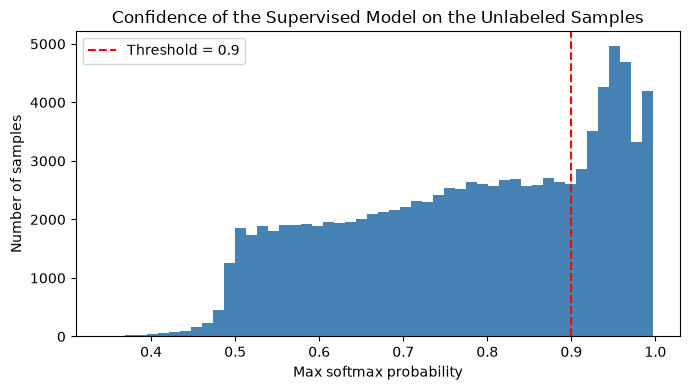


Accepted pseudo-labels saved to: ..\data\accepted_pseudo_labels.csv


In [39]:
total_unlabeled = len(pseudo_df)
accepted_count = len(accepted_pseudo_df)
accepted_percentage = accepted_count / total_unlabeled * 100

print("Total unlabeled samples:", total_unlabeled)
print("Accepted pseudo-labels:", accepted_count)
print(f"Accepted percentage: {accepted_percentage:.2f}%")
print("Rejected samples:", total_unlabeled - accepted_count)

print("\nAccepted pseudo-label class distribution:")
print(accepted_pseudo_df["pseudo_label"].map(ID_TO_RECOMMENDATION).value_counts())

print("\nAcceptance rate per predicted class:")
acceptance_by_class = (
    all_pseudo_predictions.assign(
        accepted=all_pseudo_predictions["confidence"] >= CONFIDENCE_THRESHOLD,
        predicted_class=all_pseudo_predictions["pseudo_label"].map(ID_TO_RECOMMENDATION)
    )
    .groupby("predicted_class")["accepted"]
    .agg(total="size", accepted="sum", rate="mean")
)
display(acceptance_by_class.round(4))

plt.figure(figsize=(7, 4))
plt.hist(all_pseudo_predictions["confidence"], bins=50, color="steelblue")
plt.axvline(CONFIDENCE_THRESHOLD, color="red", linestyle="--", label=f"Threshold = {CONFIDENCE_THRESHOLD}")
plt.title("Confidence of the Supervised Model on the Unlabeled Samples")
plt.xlabel("Max softmax probability")
plt.ylabel("Number of samples")
plt.legend()
plt.tight_layout()
plt.show()

PSEUDO_PREDICTIONS_PATH = DATA_DIR / "accepted_pseudo_labels.csv"
accepted_pseudo_df.to_csv(PSEUDO_PREDICTIONS_PATH, index=False, encoding="utf-8-sig")
print("\nAccepted pseudo-labels saved to:", PSEUDO_PREDICTIONS_PATH)

## Step 3: Build the Combined Training Set

The accepted pseudo-labeled samples are added to the 80% labeled data. Pseudo-labels are used only for the recommendation task.

In [ ]:

# -----------------------------------------
# 1. Prepare accepted pseudo-labeled samples
# -----------------------------------------

accepted_for_training = accepted_pseudo_df[
    ["id", "text", "pseudo_label"]
].copy()

accepted_for_training["recommendation_label"] = (
    accepted_for_training["pseudo_label"].astype(int)
)


# -----------------------------------------
# 2. Prepare supervised samples
# -----------------------------------------

supervised_for_training = train_df[
    ["id", "text", "recommendation_label"]
].copy()


# -----------------------------------------
# 3. Combine both datasets
# -----------------------------------------

combined_train_df = pd.concat(
    [
        supervised_for_training,
        accepted_for_training[
            ["id", "text", "recommendation_label"]
        ]
    ],
    ignore_index=True
)


# -----------------------------------------
# 4. Safety checks
# -----------------------------------------

assert combined_train_df["id"].is_unique

assert set(supervised_for_training["id"]).isdisjoint(
    set(accepted_for_training["id"])
)


# -----------------------------------------
# 5. Display dataset information
# -----------------------------------------

print("Supervised samples:", len(supervised_for_training))
print("Accepted pseudo-labeled samples:", len(accepted_for_training))
print("Combined training samples:", len(combined_train_df))


# -----------------------------------------
# 6. Create Dataset
# -----------------------------------------

set_seed(SEED)

combined_dataset = ReviewDataset(
    combined_train_df,
    tokenizer,
    max_length=MAX_LENGTH,
    cache_name="combined_semi_supervised"
)


# -----------------------------------------
# 7. Create DataLoader
# -----------------------------------------

combined_loader = DataLoader(
    combined_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=torch.cuda.is_available(),
    collate_fn=dynamic_padding_collate
)


Supervised samples: 400000
Accepted pseudo-labeled samples: 28311
Combined training samples: 428311
[combined_semi_supervised] Loading existing token cache...
[combined_semi_supervised] Dataset ready: 428,311 samples


## Step 4: Semi-Supervised Training (labeled + pseudo-labeled)

A **new** model is created from the pretrained ParsBERT encoder with the same seed and the same hyperparameters as the baseline, then trained on the combined dataset.

In [ ]:
semi_model, semi_history_df = train_model(
    "Semi-Supervised",
    combined_loader,
    SEMI_CHECKPOINT_PATH,
    SEMI_HISTORY_PATH,
    initial_model_state=supervised_model.state_dict()
)

display(semi_history_df.round(4))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: HooshvareLab/bert-fa-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[Semi-Supervised] Initialized from supervised model.
[Semi-Supervised] No checkpoint found. Starting training from scratch.

[Semi-Supervised] Epoch 1/10
--------------------------------------------------


Semi-Supervised Training:   0%|          | 0/53539 [00:00<?, ?it/s]

Semi-Supervised Validation:   0%|          | 0/6250 [00:00<?, ?it/s]


Train Loss: 0.5181
Validation Loss: 0.5204
Train Accuracy: 0.7812
Validation Accuracy: 0.7770
Train Macro F1: 0.7770
Validation Macro F1: 0.7764

[Semi-Supervised] New best checkpoint saved!
[Semi-Supervised] Latest checkpoint saved: /content/drive/MyDrive/digikala_comments/models/parsbert_semi_supervised_latest.pt

[Semi-Supervised] Epoch 2/10
--------------------------------------------------


Semi-Supervised Training:   0%|          | 0/53539 [00:00<?, ?it/s]

### Continue Training

In [ ]:
print("Continue Training")
semi_model, semi_history_df = train_model(
    "Semi-Supervised",
    combined_loader,
    SEMI_CHECKPOINT_PATH,
    SEMI_HISTORY_PATH,
    initial_model_state=supervised_model.state_dict()
)

display(semi_history_df.round(4))

Continue Training


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: HooshvareLab/bert-fa-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[Semi-Supervised] Initialized from supervised model.
[Semi-Supervised] Loading checkpoint: /content/drive/MyDrive/digikala_comments/models/parsbert_semi_supervised_latest.pt
[Semi-Supervised] Last completed epoch: 1/10
[Semi-Supervised] Best Validation Macro F1: 0.7764

[Semi-Supervised] Epoch 2/10
--------------------------------------------------


Semi-Supervised Training:   0%|          | 0/53539 [00:00<?, ?it/s]

Semi-Supervised Validation:   0%|          | 0/6250 [00:00<?, ?it/s]


Train Loss: 0.3825
Validation Loss: 0.6318
Train Accuracy: 0.8495
Validation Accuracy: 0.7618
Train Macro F1: 0.8466
Validation Macro F1: 0.7623

[Semi-Supervised] No improvement for 1 epoch(s).
[Semi-Supervised] Latest checkpoint saved: /content/drive/MyDrive/digikala_comments/models/parsbert_semi_supervised_latest.pt

[Semi-Supervised] Epoch 3/10
--------------------------------------------------


Semi-Supervised Training:   0%|          | 0/53539 [00:00<?, ?it/s]

### Training Curves (both models)

In [15]:
import pandas as pd
from pathlib import Path

# Define history file paths
DATA_DIR = Path("../data")

SUPERVISED_HISTORY_PATH = DATA_DIR / "supervised_training_history.csv"
SEMI_HISTORY_PATH = DATA_DIR / "semi_supervised_training_history.csv"

# Load saved training histories
supervised_history_df = pd.read_csv(
    SUPERVISED_HISTORY_PATH
)

semi_history_df = pd.read_csv(
    SEMI_HISTORY_PATH
)

print("Training histories loaded successfully!")

display(supervised_history_df.head())
display(semi_history_df.head())

Training histories loaded successfully!


,epoch,train_loss,val_loss,train_accuracy,val_accuracy,train_macro_f1,val_macro_f1
0,1,0.609300,0.527064,0.735747,0.77574,0.734765,0.775178
1,2,0.477693,0.583066,0.802072,0.76506,0.801505,0.763676
2,3,0.516731,0.536028,0.783408,0.77248,0.782875,0.772694
3,4,0.465156,0.580301,0.809778,0.76720,0.809360,0.761979


,epoch,train_loss,val_loss,train_accuracy,val_accuracy,train_macro_f1,val_macro_f1
0,1,0.518055,0.520395,0.781161,0.77702,0.776974,0.776375
1,2,0.382506,0.631772,0.849472,0.76184,0.846638,0.762315


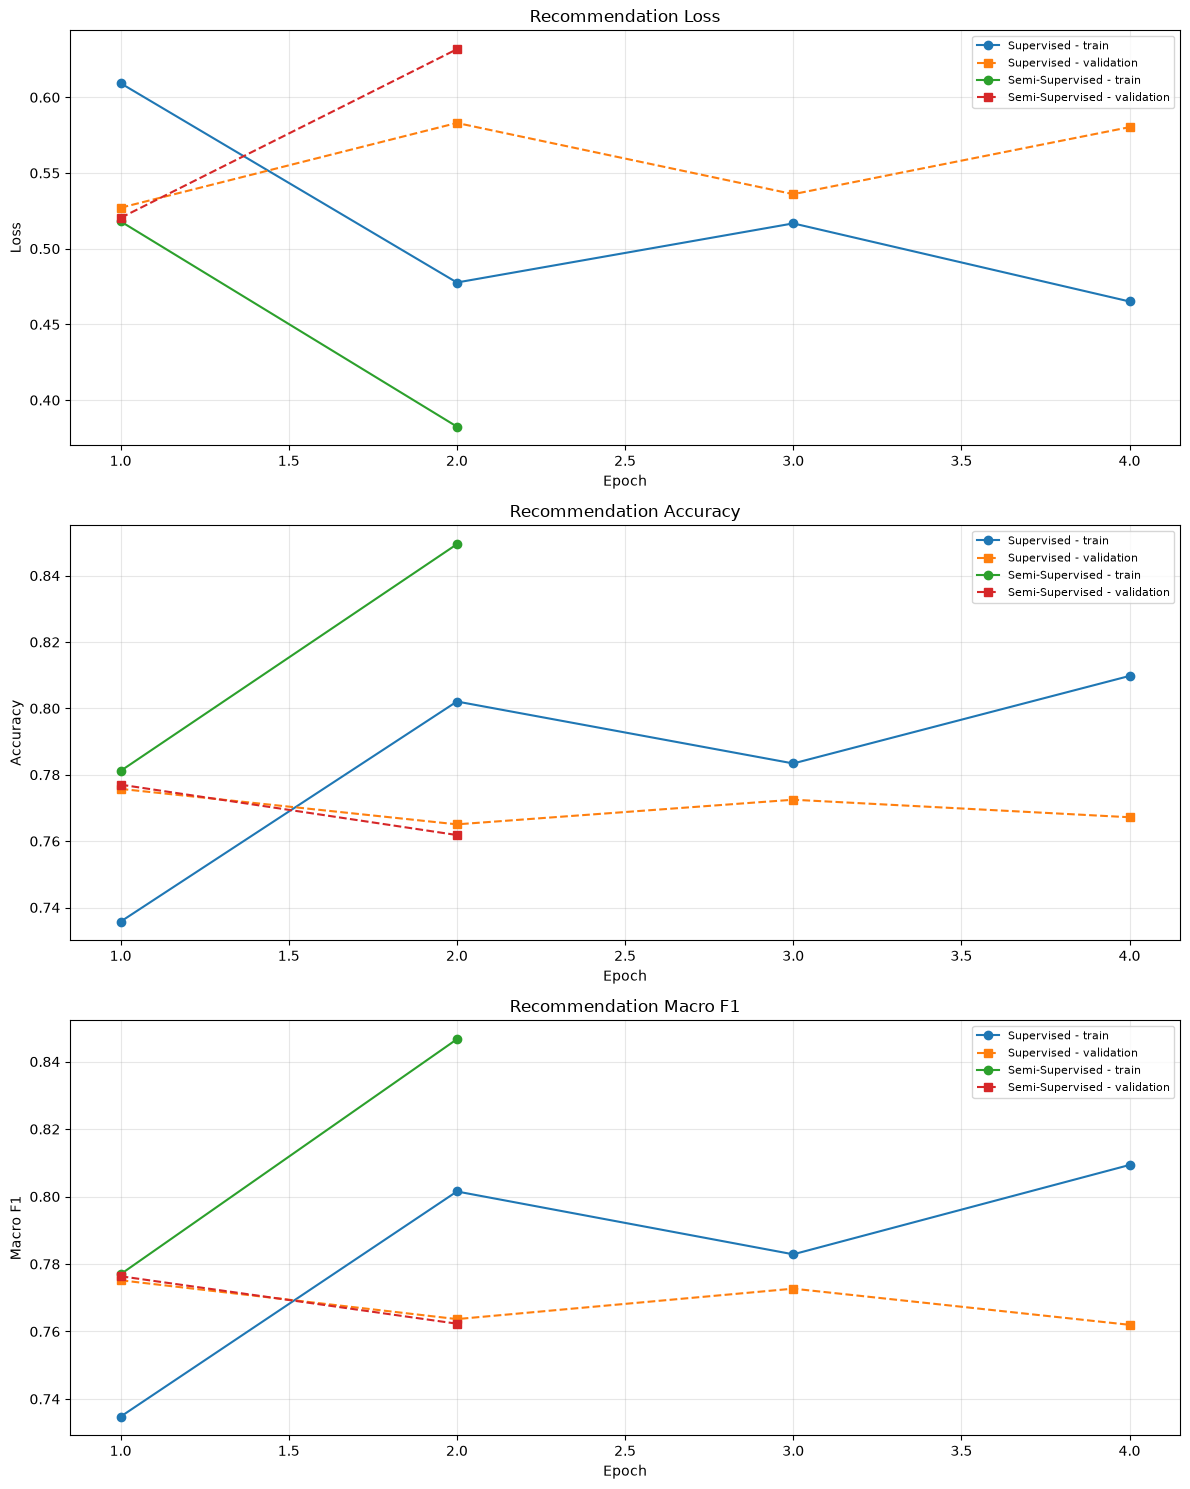

Note: Semi-Supervised training metrics include pseudo-labeled samples.


In [16]:
fig, axes = plt.subplots(3, 1, figsize=(12, 15))

for name, hist in [
    ("Supervised", supervised_history_df),
    ("Semi-Supervised", semi_history_df)
]:

    # Recommendation Loss
    axes[0].plot(
        hist["epoch"],
        hist["train_loss"],
        marker="o",
        label=f"{name} - train"
    )

    axes[0].plot(
        hist["epoch"],
        hist["val_loss"],
        marker="s",
        linestyle="--",
        label=f"{name} - validation"
    )

    # Recommendation Accuracy
    axes[1].plot(
        hist["epoch"],
        hist["train_accuracy"],
        marker="o",
        label=f"{name} - train"
    )

    axes[1].plot(
        hist["epoch"],
        hist["val_accuracy"],
        marker="s",
        linestyle="--",
        label=f"{name} - validation"
    )

    # Recommendation Macro F1
    axes[2].plot(
        hist["epoch"],
        hist["train_macro_f1"],
        marker="o",
        label=f"{name} - train"
    )

    axes[2].plot(
        hist["epoch"],
        hist["val_macro_f1"],
        marker="s",
        linestyle="--",
        label=f"{name} - validation"
    )

axes[0].set_title("Recommendation Loss")
axes[1].set_title("Recommendation Accuracy")
axes[2].set_title("Recommendation Macro F1")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel("Loss")
axes[1].set_ylabel("Accuracy")
axes[2].set_ylabel("Macro F1")

plt.tight_layout()
plt.show()

print(
    "Note: Semi-Supervised training metrics include "
    "pseudo-labeled samples."
)


## Step 5: Evaluation on Two Datasets

Both models are evaluated, with identical loaders, on:

- **Test set** (`test.csv`): never used for training, pseudo-labeling, or model selection.
- **Real Test Set** (`test_10k_corrected`) : The original test dataset extracted from the original data.

For each model and dataset we report Accuracy, Macro Precision/Recall/F1, Weighted F1, loss, the classification report, the confusion matrix, and the row-normalized confusion matrix.

In [29]:
import torch
from pathlib import Path

# Use the existing device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Check checkpoint files
print("Supervised checkpoint:", SUPERVISED_CHECKPOINT_PATH)
print("Semi-supervised checkpoint:", SEMI_CHECKPOINT_PATH)

assert Path(SUPERVISED_CHECKPOINT_PATH).exists()
assert Path(SEMI_CHECKPOINT_PATH).exists()


def load_model_from_checkpoint(checkpoint_path):
    """
    Load a trained MultiTaskParsBERT model from a checkpoint.
    """

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    # Support both full checkpoints and raw state dictionaries.
    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    elif "model_state" in checkpoint:
        state_dict = checkpoint["model_state"]
    elif "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
    else:
        state_dict = checkpoint

    # Create the model architecture.
    model = MultiTaskParsBERT(
        MODEL_NAME,
        NUM_CLASSES,
        NUM_CLASSES
    ).to(DEVICE)


    model.load_state_dict(state_dict)
    model.to(DEVICE)
    model.eval()

    return model


# Load both trained models
supervised_model = load_model_from_checkpoint(
    SUPERVISED_CHECKPOINT_PATH
)

semi_model = load_model_from_checkpoint(
    SEMI_CHECKPOINT_PATH
)

print("Both models loaded successfully!")
print("Device:", DEVICE)

Supervised checkpoint: ..\models\parsbert_supervised_80.pt
Semi-supervised checkpoint: ..\models\parsbert_semi_supervised.pt


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 17829.80it/s]
[transformers] BertModel LOAD REPORT from: HooshvareLab/bert-fa-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 199/199 [00:00<0

Both models loaded successfully!
Device: cpu


In [30]:

TASKS = {
    "Recommendation Status": {
        "logits_key": "recommendation_logits",
        "labels_key": "recommendation_labels",
        "class_names": [
            "recommended",
            "not_recommended",
            "no_idea"
        ]
    }
}

EVAL_SETS = {
    "Test": test_loader,
    "Real_Test" : new_test_loader
}


@torch.no_grad()
def predict_dataset(model, data_loader, desc):
    """Predictions for both tasks; samples with label -100 are skipped."""

    model.eval()
    out = {t: {"y_true": [], "y_pred": [], "loss_sum": 0.0} for t in TASKS}

    for batch in tqdm(data_loader, desc=desc):

        input_ids = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)

        for task_name, info in TASKS.items():
            labels = batch[info["labels_key"]].to(DEVICE)
            valid = labels != -100

            if valid.any():
                logits = outputs[info["logits_key"]][valid]
                out[task_name]["loss_sum"] += F.cross_entropy(
                    logits, labels[valid], reduction="sum"
                ).item()
                out[task_name]["y_true"].extend(labels[valid].cpu().tolist())
                out[task_name]["y_pred"].extend(logits.argmax(dim=1).cpu().tolist())

    for task_name in TASKS:
        y_true = np.asarray(out[task_name]["y_true"], dtype=int)
        out[task_name]["y_true"] = y_true
        out[task_name]["y_pred"] = np.asarray(out[task_name]["y_pred"], dtype=int)
        out[task_name]["loss"] = out[task_name].pop("loss_sum") / max(len(y_true), 1)

    return out


def calculate_metrics(y_true, y_pred):
    precision, recall, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=[0, 1, 2], average="macro", zero_division=0
    )
    weighted_f1 = precision_recall_fscore_support(
        y_true, y_pred, labels=[0, 1, 2], average="weighted", zero_division=0
    )[2]

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (Macro)": precision,
        "Recall (Macro)": recall,
        "F1 (Macro)": macro_f1,
        "F1 (Weighted)": weighted_f1,
    }


MODELS = {"Supervised": supervised_model, "Semi-Supervised": semi_model}

# results[model][dataset][task] -> {"y_true", "y_pred", "loss"}
results = {
    model_name: {
        set_name: predict_dataset(model, loader, f"{model_name} on {set_name}")
        for set_name, loader in EVAL_SETS.items()
    }
    for model_name, model in MODELS.items()
}

# Both models must be scored against exactly the same labels.
for set_name in EVAL_SETS:
    for task_name in TASKS:
        assert np.array_equal(
            results["Supervised"][set_name][task_name]["y_true"],
            results["Semi-Supervised"][set_name][task_name]["y_true"]
        )

print("Predictions collected for both models on both datasets.")

Semi-Supervised on Real_Test: 100%|██████████| 1250/1250 [12:55<00:00,  1.61it/s]

Predictions collected for both models on both datasets.


### Metric Comparison: Supervised vs. Semi-Supervised

In [31]:
rows = []

for set_name in EVAL_SETS:
    for task_name in TASKS:
        sup = results["Supervised"][set_name][task_name]
        semi = results["Semi-Supervised"][set_name][task_name]

        sup_m = calculate_metrics(sup["y_true"], sup["y_pred"])
        semi_m = calculate_metrics(semi["y_true"], semi["y_pred"])

        sup_m["Loss"] = sup["loss"]
        semi_m["Loss"] = semi["loss"]

        rows.append({"Dataset": set_name, "Task": task_name, "Model": "Supervised", **sup_m})
        rows.append({"Dataset": set_name, "Task": task_name, "Model": "Semi-Supervised", **semi_m})
        rows.append({
            "Dataset": set_name, "Task": task_name, "Model": "Change (Semi - Supervised)",
            **{k: semi_m[k] - sup_m[k] for k in sup_m}
        })

comparison_df = pd.DataFrame(rows).set_index(["Dataset", "Task", "Model"])

print("Number of evaluated samples:")
for set_name in EVAL_SETS:
    for task_name in TASKS:
        n = len(results["Supervised"][set_name][task_name]["y_true"])
        print(f"  {set_name} / {task_name}: {n:,}")

print("\nPositive change = the semi-supervised model is better (for Loss, negative is better).")
display(comparison_df.round(4))

Number of evaluated samples:
  Test / Recommendation Status: 10,000
  Real_Test / Recommendation Status: 10,000

Positive change = the semi-supervised model is better (for Loss, negative is better).


Accuracy  \
Dataset   Task                  Model                                  
Test      Recommendation Status Supervised                    0.9028   
                                Semi-Supervised               0.8942   
                                Change (Semi - Supervised)   -0.0086   
Real_Test Recommendation Status Supervised                    0.8013   
                                Semi-Supervised               0.7979   
                                Change (Semi - Supervised)   -0.0034   

                                                            Precision (Macro)  \
Dataset   Task                  Model                                           
Test      Recommendation Status Supervised                             0.9005   
                                Semi-Supervised                        0.8917   
                                Change (Semi - Supervised)            -0.0088   
Real_Test Recommendation Status Supervised                             0.8070   
                                Semi-Supervised                        0.8031   
                                Change (Semi - Supervised)            -0.0039   

                                                            Recall (Macro)  \
Dataset   Task                  Model                                        
Test      Recommendation Status Supervised                          0.8990   
                                Semi-Supervised                     0.8919   
                                Change (Semi - Supervised)         -0.0071   
Real_Test Recommendation Status Supervised                          0.8002   
                                Semi-Supervised                     0.7951   
                                Change (Semi - Supervised)         -0.0051   

                                                            F1 (Macro)  \
Dataset   Task                  Model                                    
Test      Recommendation Status Supervised                      0.8994   
                                Semi-Supervised                 0.8911   
                                Change (Semi - Supervised)     -0.0083   
Real_Test Recommendation Status Supervised                      0.8013   
                                Semi-Supervised                 0.7970   
                                Change (Semi - Supervised)     -0.0043   

                                                            F1 (Weighted)  \
Dataset   Task                  Model                                       
Test      Recommendation Status Supervised                         0.9032   
                                Semi-Supervised                    0.8950   
                                Change (Semi - Supervised)        -0.0082   
Real_Test Recommendation Status Supervised                         0.8050   
                                Semi-Supervised                    0.8010   
                                Change (Semi - Supervised)        -0.0039   

                                                              Loss  
Dataset   Task                  Model                               
Test      Recommendation Status Supervised                  0.3332  
                                Semi-Supervised             0.3228  
                                Change (Semi - Supervised) -0.0104  
Real_Test Recommendation Status Supervised                  0.4812  
                                Semi-Supervised             0.4808  
                                Change (Semi - Supervised) -0.0004

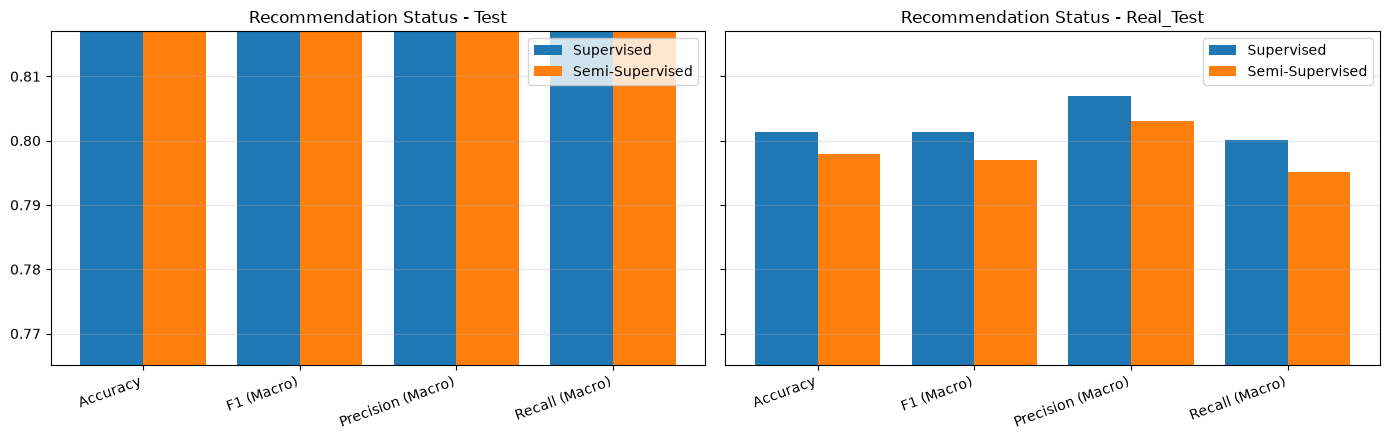

In [32]:
# Bar chart of the main metrics, recommendation task
metrics_to_plot = ["Accuracy", "F1 (Macro)", "Precision (Macro)", "Recall (Macro)"]

fig, axes = plt.subplots(1, len(EVAL_SETS), figsize=(14, 4.5), sharey=True)

for ax, set_name in zip(np.atleast_1d(axes), EVAL_SETS):
    sup_vals = [comparison_df.loc[(set_name, "Recommendation Status", "Supervised"), m] for m in metrics_to_plot]
    semi_vals = [comparison_df.loc[(set_name, "Recommendation Status", "Semi-Supervised"), m] for m in metrics_to_plot]

    x = np.arange(len(metrics_to_plot))
    ax.bar(x - 0.2, sup_vals, width=0.4, label="Supervised")
    ax.bar(x + 0.2, semi_vals, width=0.4, label="Semi-Supervised")

    lo = min(sup_vals + semi_vals)
    ax.set_ylim(max(lo - 0.03, 0), min(max(sup_vals + semi_vals) + 0.01, 1.0))
    ax.set_xticks(x)
    ax.set_xticklabels(metrics_to_plot, rotation=20, ha="right")
    ax.set_title(f"Recommendation Status - {set_name}")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

### Is the Difference Statistically Meaningful?

A small accuracy difference can be noise. We apply an exact McNemar test (paired, same samples) on the recommendation task: it only looks at the samples where exactly one of the two models is correct. We also report a paired bootstrap 95% confidence interval for the accuracy difference.

In [33]:
from scipy.stats import binomtest

rng = np.random.default_rng(SEED)
significance_rows = []

for set_name in EVAL_SETS:
    sup = results["Supervised"][set_name]["Recommendation Status"]
    semi = results["Semi-Supervised"][set_name]["Recommendation Status"]

    y_true = sup["y_true"]
    sup_correct = (sup["y_pred"] == y_true)
    semi_correct = (semi["y_pred"] == y_true)

    only_sup = int((sup_correct & ~semi_correct).sum())   # supervised right, semi wrong
    only_semi = int((~sup_correct & semi_correct).sum())  # semi right, supervised wrong
    discordant = only_sup + only_semi

    p_value = binomtest(only_semi, discordant, 0.5).pvalue if discordant > 0 else 1.0

    # Paired bootstrap of the accuracy difference
    diff = semi_correct.astype(float) - sup_correct.astype(float)
    boot = np.array([
        diff[rng.integers(0, len(diff), len(diff))].mean() for _ in range(2000)
    ])
    ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

    significance_rows.append({
        "Dataset": set_name,
        "Samples": len(y_true),
        "Only supervised correct": only_sup,
        "Only semi correct": only_semi,
        "Accuracy diff (semi - sup)": diff.mean(),
        "95% CI low": ci_low,
        "95% CI high": ci_high,
        "McNemar p-value": p_value,
        "Significant (p<0.05)": p_value < 0.05,
    })

significance_df = pd.DataFrame(significance_rows).set_index("Dataset")
display(significance_df.round(4))

,Samples,Only supervised correct,Only semi correct,Accuracy diff (semi - sup),95% CI low,95% CI high,McNemar p-value,Significant (p<0.05)
Dataset,,,,,,,,
Test,10000,352,266,-0.0086,-0.0133,-0.0036,0.0006,True
Real_Test,10000,470,436,-0.0034,-0.0093,0.0024,0.2729,False


### Classification Reports and Confusion Matrices

Supervised | Test | Recommendation Status
                 precision    recall  f1-score   support

    recommended     0.9369    0.9251    0.9310      4314
not_recommended     0.9250    0.8868    0.9055      2658
        no_idea     0.8396    0.8851    0.8617      3028

       accuracy                         0.9028     10000
      macro avg     0.9005    0.8990    0.8994     10000
   weighted avg     0.9043    0.9028    0.9032     10000



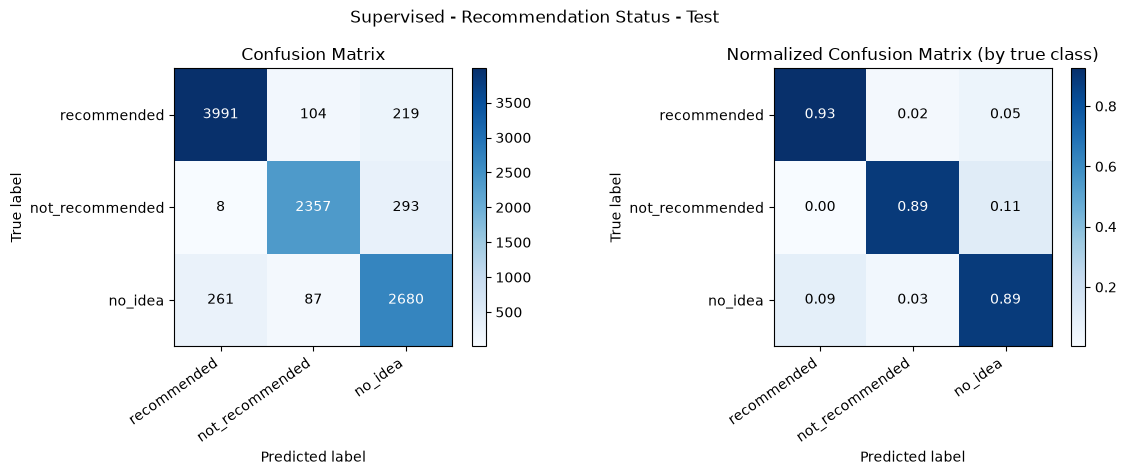

Semi-Supervised | Test | Recommendation Status
                 precision    recall  f1-score   support

    recommended     0.9402    0.9073    0.9234      4314
not_recommended     0.9167    0.8822    0.8992      2658
        no_idea     0.8182    0.8861    0.8508      3028

       accuracy                         0.8942     10000
      macro avg     0.8917    0.8919    0.8911     10000
   weighted avg     0.8970    0.8942    0.8950     10000



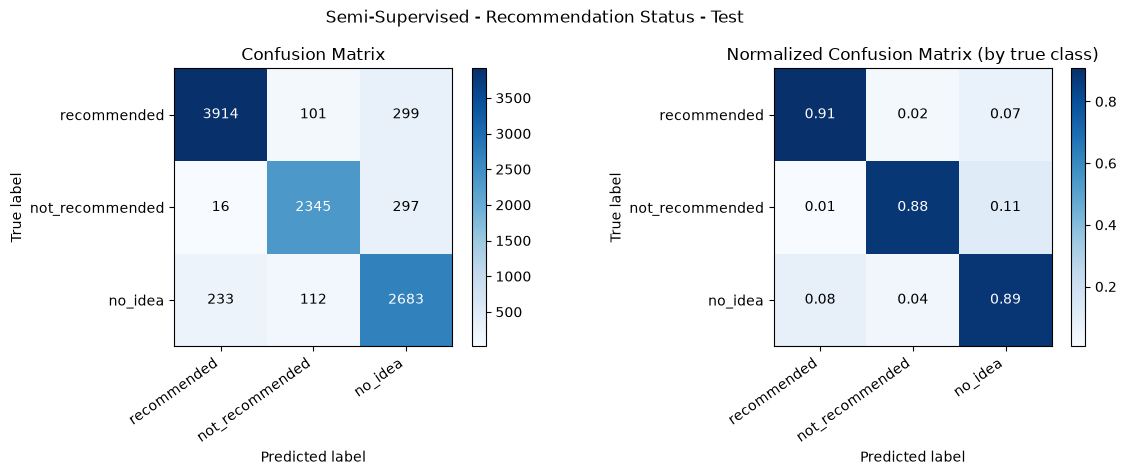

Supervised | Real_Test | Recommendation Status
                 precision    recall  f1-score   support

    recommended     0.9154    0.8314    0.8714      3369
not_recommended     0.8478    0.8017    0.8241      3600
        no_idea     0.6578    0.7674    0.7084      3031

       accuracy                         0.8013     10000
      macro avg     0.8070    0.8002    0.8013     10000
   weighted avg     0.8130    0.8013    0.8050     10000



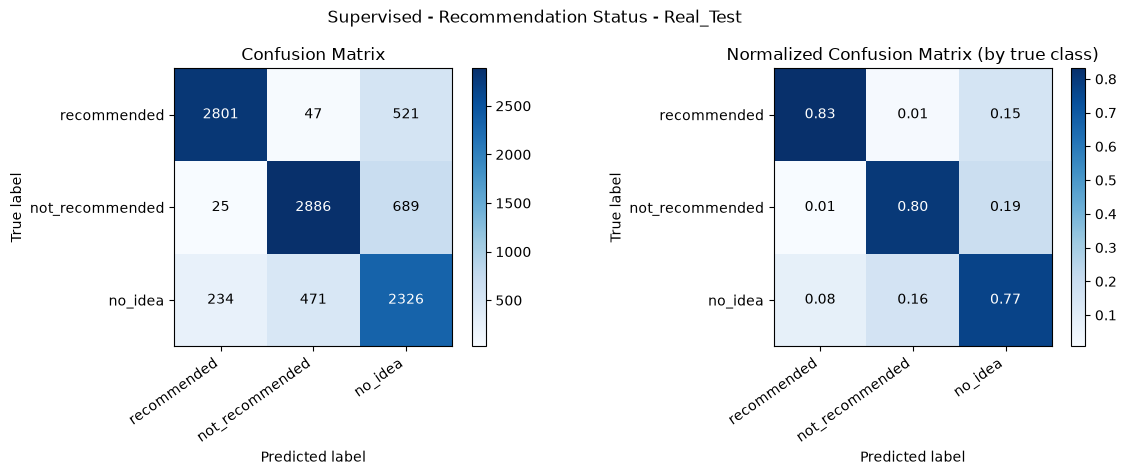

Semi-Supervised | Real_Test | Recommendation Status
                 precision    recall  f1-score   support

    recommended     0.9292    0.8097    0.8653      3369
not_recommended     0.8189    0.8364    0.8275      3600
        no_idea     0.6614    0.7390    0.6980      3031

       accuracy                         0.7979     10000
      macro avg     0.8031    0.7951    0.7970     10000
   weighted avg     0.8083    0.7979    0.8010     10000



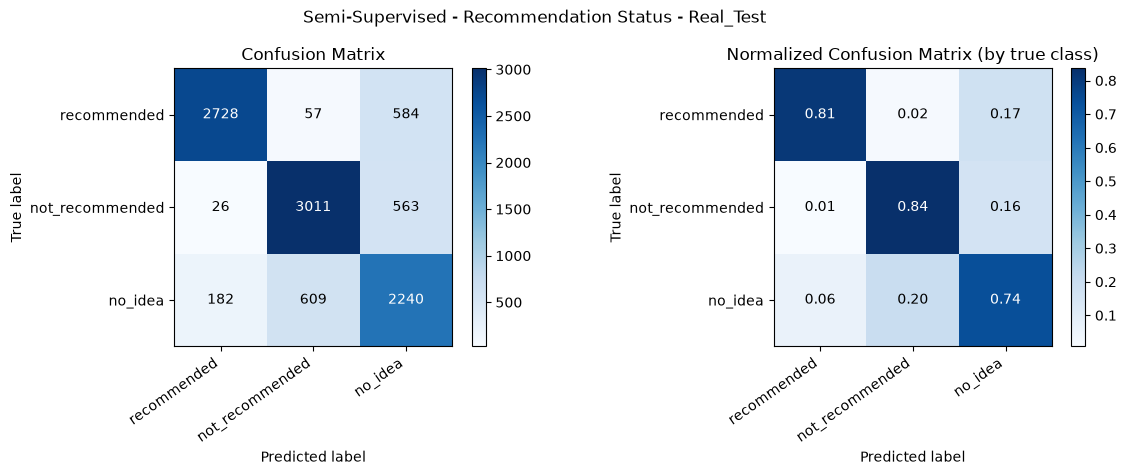

In [34]:
def plot_confusion_pair(y_true, y_pred, class_names, title):
    """Raw and row-normalized confusion matrices side by side."""

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

    for ax, matrix, sub_title, fmt in [
        (axes[0], cm, "Confusion Matrix", "d"),
        (axes[1], cm_norm, "Normalized Confusion Matrix (by true class)", ".2f"),
    ]:
        im = ax.imshow(matrix, interpolation="nearest", cmap="Blues")
        ax.set_title(sub_title)
        ax.set_xlabel("Predicted label")
        ax.set_ylabel("True label")
        ax.set_xticks(range(3))
        ax.set_xticklabels(class_names, rotation=35, ha="right")
        ax.set_yticks(range(3))
        ax.set_yticklabels(class_names)

        threshold = matrix.max() / 2
        for r in range(3):
            for c in range(3):
                ax.text(
                    c, r, format(matrix[r, c], fmt), ha="center", va="center",
                    color="white" if matrix[r, c] > threshold else "black"
                )

        fig.colorbar(im, ax=ax, fraction=0.046)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


for set_name in EVAL_SETS:
    for model_name in MODELS:
        for task_name, info in TASKS.items():

            y_true = results[model_name][set_name][task_name]["y_true"]
            y_pred = results[model_name][set_name][task_name]["y_pred"]

            print("=" * 70)
            print(f"{model_name} | {set_name} | {task_name}")
            print("=" * 70)

            print(classification_report(
                y_true, y_pred, labels=[0, 1, 2],
                target_names=info["class_names"], digits=4, zero_division=0
            ))

            plot_confusion_pair(
                y_true, y_pred, info["class_names"],
                f"{model_name} - {task_name} - {set_name}"
            )

## Pseudo-Label Quality Audit

Now that selection and training are finished, we compare the pseudo-labels with the hidden reference labels. We also sweep the confidence threshold (without retraining) to show the trade-off between the number of accepted samples and their label accuracy.

Accepted pseudo-labels: 28811
Pseudo-label accuracy (accepted, threshold 0.9): 0.9465
Accuracy of the rejected predictions: 0.7004
Accuracy on all 100k unlabeled samples: 0.7713

Per-class audit of accepted pseudo-labels (by reference class):


,accepted,pseudo_label_accuracy
recommendation_status,,
no_idea,1994,0.3566
not_recommended,13831,0.9866
recommended,12986,0.9945



Predicted pseudo-label distribution:
pseudo_label
not_recommended    14534
recommended        13495
no_idea              782
Name: count, dtype: int64

Reference label distribution of accepted samples:
recommendation_status
not_recommended    13831
recommended        12986
no_idea             1994
Name: count, dtype: int64

Pseudo-label confusion matrix (accepted samples):


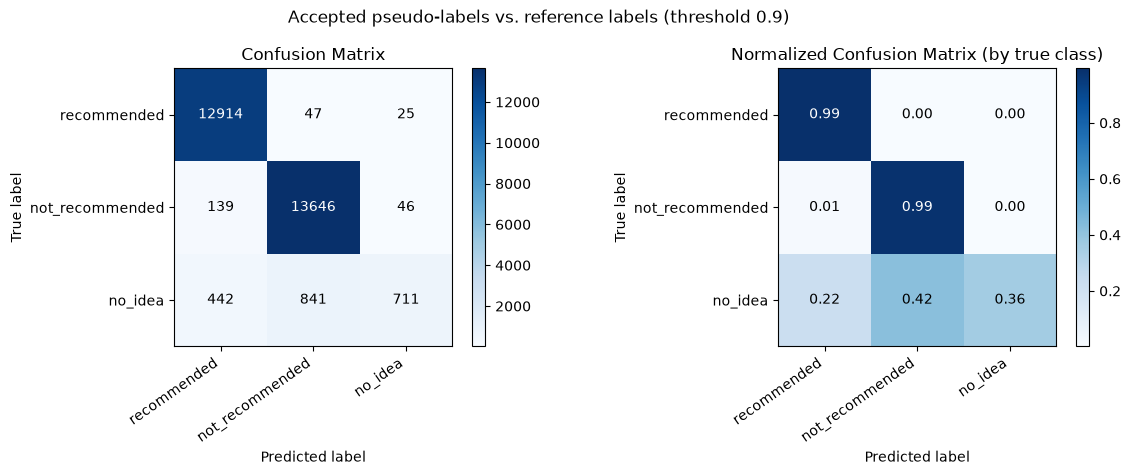


Confidence-threshold sweep:


,Accepted,Accepted %,Pseudo-label accuracy
Threshold,,,
0.50,97522,97.522,0.7793
0.60,83256,83.256,0.8193
0.70,67755,67.755,0.8600
0.80,48947,48.947,0.9048
0.90,28811,28.811,0.9465
0.95,15013,15.013,0.9653
0.99,1896,1.896,0.9947


In [37]:
reference_df = pd.read_csv(
    DATA_DIR / "train_experiment_500k.csv",
    usecols=["id", "recommendation_status"]
)

audit_all_df = all_pseudo_predictions.merge(
    reference_df, on="id", how="left", validate="one_to_one"
)

if audit_all_df["recommendation_status"].isna().any():
    raise ValueError("Some reference labels are missing from the pseudo-label audit.")

audit_all_df["reference_label"] = audit_all_df["recommendation_status"].map(RECOMMENDATION_LABELS)
audit_all_df["correct"] = audit_all_df["reference_label"] == audit_all_df["pseudo_label"]

audit_df = audit_all_df[audit_all_df["confidence"] >= CONFIDENCE_THRESHOLD].copy()

pseudo_label_accuracy = audit_df["correct"].mean()
rejected_accuracy = audit_all_df.loc[audit_all_df["confidence"] < CONFIDENCE_THRESHOLD, "correct"].mean()

print("Accepted pseudo-labels:", len(audit_df))
print(f"Pseudo-label accuracy (accepted, threshold {CONFIDENCE_THRESHOLD}): {pseudo_label_accuracy:.4f}")
print(f"Accuracy of the rejected predictions: {rejected_accuracy:.4f}")
print(f"Accuracy on all 100k unlabeled samples: {audit_all_df['correct'].mean():.4f}")

print("\nPer-class audit of accepted pseudo-labels (by reference class):")
display(
    audit_df.groupby("recommendation_status")["correct"]
    .agg(accepted="size", pseudo_label_accuracy="mean")
    .round(4)
)

print("\nPredicted pseudo-label distribution:")
print(audit_df["pseudo_label"].map(ID_TO_RECOMMENDATION).value_counts())

print("\nReference label distribution of accepted samples:")
print(audit_df["recommendation_status"].value_counts())

print("\nPseudo-label confusion matrix (accepted samples):")
plot_confusion_pair(
    audit_df["reference_label"].values, audit_df["pseudo_label"].values,
    TASKS["Recommendation Status"]["class_names"],
    f"Accepted pseudo-labels vs. reference labels (threshold {CONFIDENCE_THRESHOLD})"
)

# Threshold sweep (analysis only - no retraining)
sweep_rows = []
for t in [0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 0.99]:
    subset = audit_all_df[audit_all_df["confidence"] >= t]
    sweep_rows.append({
        "Threshold": t,
        "Accepted": len(subset),
        "Accepted %": len(subset) / len(audit_all_df) * 100,
        "Pseudo-label accuracy": subset["correct"].mean() if len(subset) else np.nan,
    })

threshold_sweep_df = pd.DataFrame(sweep_rows).set_index("Threshold")
print("\nConfidence-threshold sweep:")
display(threshold_sweep_df.round(4))

## Final Summary and Saved Outputs

In [40]:
rec = "Recommendation Status"

final_results = {
    "Total unlabeled samples": total_unlabeled,
    "Accepted pseudo-labels": accepted_count,
    "Accepted percentage": accepted_percentage,
    "Confidence threshold": CONFIDENCE_THRESHOLD,
    "Pseudo-label accuracy": pseudo_label_accuracy,
}

for set_name in EVAL_SETS:
    for model_name in MODELS:
        m = comparison_df.loc[(set_name, rec, model_name)]
        final_results[f"{model_name} {set_name} Accuracy"] = m["Accuracy"]
        final_results[f"{model_name} {set_name} Macro F1"] = m["F1 (Macro)"]

print("Final experiment report:")
for metric, value in final_results.items():
    print(f"{metric}: {value:.4f}" if isinstance(value, (float, np.floating)) else f"{metric}: {value}")

# Save everything
comparison_df.to_csv(DATA_DIR / "semi_supervised_comparison.csv", encoding="utf-8-sig")
significance_df.to_csv(DATA_DIR / "semi_supervised_significance.csv", encoding="utf-8-sig")
threshold_sweep_df.to_csv(DATA_DIR / "pseudo_label_threshold_sweep.csv", encoding="utf-8-sig")
audit_df.to_csv(DATA_DIR / "pseudo_label_audit.csv", index=False, encoding="utf-8-sig")
pd.Series(final_results).to_csv(DATA_DIR / "semi_supervised_final_summary.csv", header=["value"])

print("\nAll experiment results saved successfully.")

Final experiment report:
Total unlabeled samples: 100000
Accepted pseudo-labels: 28811
Accepted percentage: 28.8110
Confidence threshold: 0.9000
Pseudo-label accuracy: 0.9465
Supervised Test Accuracy: 0.9028
Supervised Test Macro F1: 0.8994
Semi-Supervised Test Accuracy: 0.8942
Semi-Supervised Test Macro F1: 0.8911
Supervised Real_Test Accuracy: 0.8013
Supervised Real_Test Macro F1: 0.8013
Semi-Supervised Real_Test Accuracy: 0.7979
Semi-Supervised Real_Test Macro F1: 0.7970

All experiment results saved successfully.


In [41]:
import json
from pathlib import Path

# Create the artifact directory
ARTIFACT_DIR = Path("../artifacts/semi_supervised")

ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Move the model to the selected device
semi_model = semi_model.to(device)

# Set the model to evaluation mode
semi_model.eval()

# Save model weights
MODEL_PATH = ARTIFACT_DIR / "model_state_dict.pt"

torch.save(
    semi_model.state_dict(),
    MODEL_PATH
)

# Save the tokenizer
TOKENIZER_DIR = ARTIFACT_DIR / "tokenizer"

tokenizer.save_pretrained(TOKENIZER_DIR)

# Find the best validation epoch
best_epoch_index = semi_history_df["val_macro_f1"].idxmax()

best_row = semi_history_df.loc[best_epoch_index]

best_epoch = int(best_row["epoch"])
best_validation_macro_f1 = float(best_row["val_macro_f1"])

# Prepare metadata
metadata = {
    "model_name": MODEL_NAME,
    "model_type": "Semi-Supervised MultiTaskParsBERT",
    "training_method": "Pseudo Labeling",
    "max_length": MAX_LENGTH,
    "dropout_rate": 0.3,
    "num_classes": NUM_CLASSES,
    "recommendation_labels": RECOMMENDATION_LABELS,
    "rating_head_trained": False,
    "confidence_threshold": CONFIDENCE_THRESHOLD,
    "best_epoch": best_epoch,
    "best_validation_macro_f1": best_validation_macro_f1
}

# Save metadata
METADATA_PATH = ARTIFACT_DIR / "metadata.json"

with open(METADATA_PATH, "w", encoding="utf-8") as file:
    json.dump(
        metadata,
        file,
        ensure_ascii=False,
        indent=4
    )

print("Semi-Supervised artifacts saved successfully!")

print("\nSaved files:")
print(MODEL_PATH)
print(TOKENIZER_DIR)
print(METADATA_PATH)


Semi-Supervised artifacts saved successfully!

Saved files:
..\artifacts\semi_supervised\model_state_dict.pt
..\artifacts\semi_supervised\tokenizer
..\artifacts\semi_supervised\metadata.json
